# Indian House Price Prediction Using Machine Learning

This notebook explores an Indian urban house-price dataset, trains three regression algorithms, compares their performance, tunes model parameters, and visualizes prediction errors.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the Dataset

In [2]:
df = pd.read_csv(r"C:\Users\Bhavik Parmar\Downloads\indian_house_prices_dataset.csv")
print(df.shape)
display(df.head())

(5500, 18)


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
0,AH-949625,Ahmedabad,Premium,Apartment,2,2,1802.94,1352.61,6,30,21,Unfurnished,1,1,0,2.43,10.42,127.24
1,CH-495919,Chennai,Affordable,Builder Floor,3,4,987.40,720.63,18,25,9,Semi-Furnished,1,1,1,1.94,4.00,80.42
2,MU-279153,Mumbai,Mid-Range,Villa,5,5,1189.71,966.26,0,23,20,Unfurnished,1,1,1,5.38,12.90,234.76
3,AH-454908,Ahmedabad,Mid-Range,Apartment,3,4,1407.20,1194.58,20,33,10,Unfurnished,1,1,1,5.87,10.03,52.88
4,DE-669210,Delhi,Mid-Range,Independent House,4,5,1779.58,1351.46,8,23,17,Unfurnished,0,1,0,0.99,5.23,255.47


## 3. Explore Dataset Columns

In [5]:
print(df.columns.tolist())

['Property_ID', 'City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km', 'Price_INR_Lakhs']


## 4. Review Dataset Information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Property_ID                 5500 non-null   object 
 1   City                        5500 non-null   object 
 2   Locality_Type               5500 non-null   object 
 3   Property_Type               5500 non-null   object 
 4   BHK                         5500 non-null   int64  
 5   Bathrooms                   5500 non-null   int64  
 6   Super_Area_SqFt             5500 non-null   float64
 7   Carpet_Area_SqFt            5500 non-null   float64
 8   Floor_Number                5500 non-null   int64  
 9   Total_Floors                5500 non-null   int64  
 10  Age_of_Property             5500 non-null   int64  
 11  Furnishing_Status           5500 non-null   object 
 12  Parking                     5500 non-null   int64  
 13  Lift_Available              5500 

## 5. Display the Last Five Records

In [6]:
display(df.tail())

,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
5495,KO-381811,Kolkata,Mid-Range,Villa,2,3,760.16,545.01,1,2,2,Semi-Furnished,0,0,0,6.78,13.03,42.58
5496,KO-710998,Kolkata,Mid-Range,Villa,2,3,808.68,627.15,4,14,32,Semi-Furnished,1,1,1,2.95,6.95,29.45
5497,KO-552070,Kolkata,Affordable,Apartment,3,4,712.17,526.90,1,2,31,Semi-Furnished,1,0,1,2.90,0.78,31.83
5498,KO-028730,Kolkata,Mid-Range,Apartment,3,3,1170.12,935.16,29,36,3,Unfurnished,1,1,0,5.66,8.52,74.16
5499,CH-771519,Chennai,Mid-Range,Independent House,2,3,1093.18,859.78,18,21,33,Furnished,0,1,1,1.81,11.54,38.47


## 6. Descriptive Statistical Summary

In [7]:
display(df.describe())

,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,2.783818,3.269273,1290.025135,968.496276,9.467273,20.089273,16.915273,0.702545,0.945636,0.599455,3.151171,8.005529,123.623386
std,1.248382,1.308290,549.561401,421.617349,8.595781,11.244680,10.173424,0.457180,0.226754,0.490054,1.822607,3.851945,123.407723
min,1.000000,1.000000,137.000000,102.290000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000,6.601908
25%,2.000000,2.000000,888.450000,658.657500,2.000000,11.000000,8.000000,0.000000,1.000000,0.000000,1.710000,5.190000,48.130000
50%,3.000000,3.000000,1178.550000,880.320000,7.000000,20.000000,17.000000,1.000000,1.000000,1.000000,3.030000,7.920000,85.240000
75%,3.000000,4.000000,1580.812500,1194.382500,15.000000,30.000000,26.000000,1.000000,1.000000,1.000000,4.420000,10.680000,152.370000
max,6.000000,6.000000,3554.950000,2903.530000,38.000000,39.000000,34.000000,1.000000,1.000000,1.000000,10.550000,21.800000,1492.828310


## 7. Check Missing Values

In [11]:
print(df.isnull().sum())

Property_ID                   0
City                          0
Locality_Type                 0
Property_Type                 0
BHK                           0
Bathrooms                     0
Super_Area_SqFt               0
Carpet_Area_SqFt              0
Floor_Number                  0
Total_Floors                  0
Age_of_Property               0
Furnishing_Status             0
Parking                       0
Lift_Available                0
Gated_Community               0
Distance_to_Metro_km          0
Distance_to_City_Center_km    0
Price_INR_Lakhs               0
dtype: int64


## 8. Separate Features and Target

In [8]:
y = df["Price_INR_Lakhs"]
X = df.drop(columns=["Price_INR_Lakhs", "Property_ID"])

print("Feature columns:")
print(X.columns.tolist())
print("\nTarget column:", y.name)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature data types:")
print(X.dtypes)

Feature columns:
['City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km']

Target column: Price_INR_Lakhs
Feature shape: (5500, 16)
Target shape: (5500,)

Feature data types:
City                           object
Locality_Type                  object
Property_Type                  object
BHK                             int64
Bathrooms                       int64
Super_Area_SqFt               float64
Carpet_Area_SqFt              float64
Floor_Number                    int64
Total_Floors                    int64
Age_of_Property                 int64
Furnishing_Status              object
Parking                         int64
Lift_Available                  int64
Gated_Community                 int64
Distance_to_Metro_km          float64
Distance_to_City_Center_km    float6

## 9. Exploratory Data Analysis (EDA)

### 9.1 Distribution of House Prices

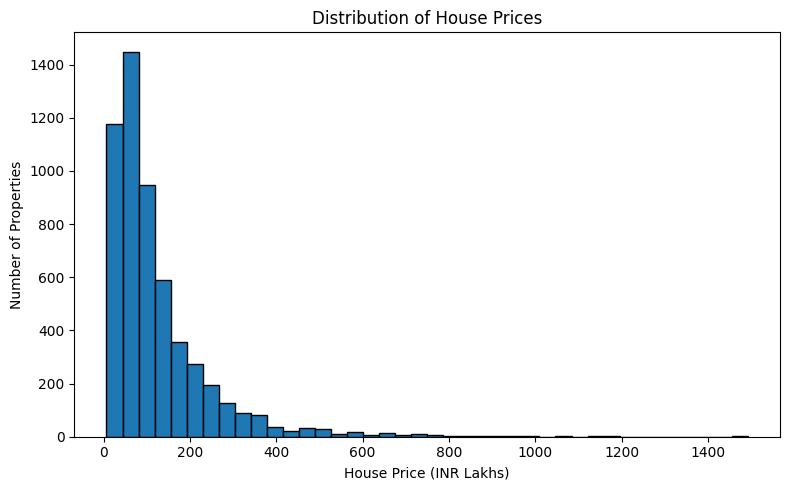

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df["Price_INR_Lakhs"], bins=40, edgecolor="black")
plt.xlabel("House Price (INR Lakhs)")
plt.ylabel("Number of Properties")
plt.title("Distribution of House Prices")
plt.tight_layout()
plt.show()

### 9.2 House Prices by Property Type

<Figure size 900x500 with 0 Axes>

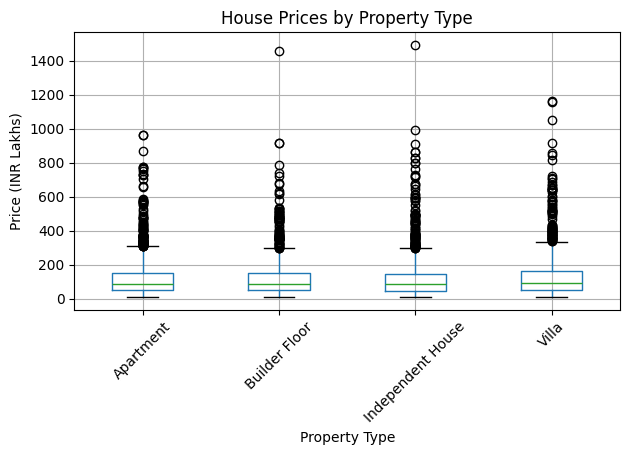

In [10]:
plt.figure(figsize=(9, 5))
df.boxplot(column="Price_INR_Lakhs", by="Property_Type", rot=45)
plt.xlabel("Property Type")
plt.ylabel("Price (INR Lakhs)")
plt.title("House Prices by Property Type")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 9.3 Correlation Analysis

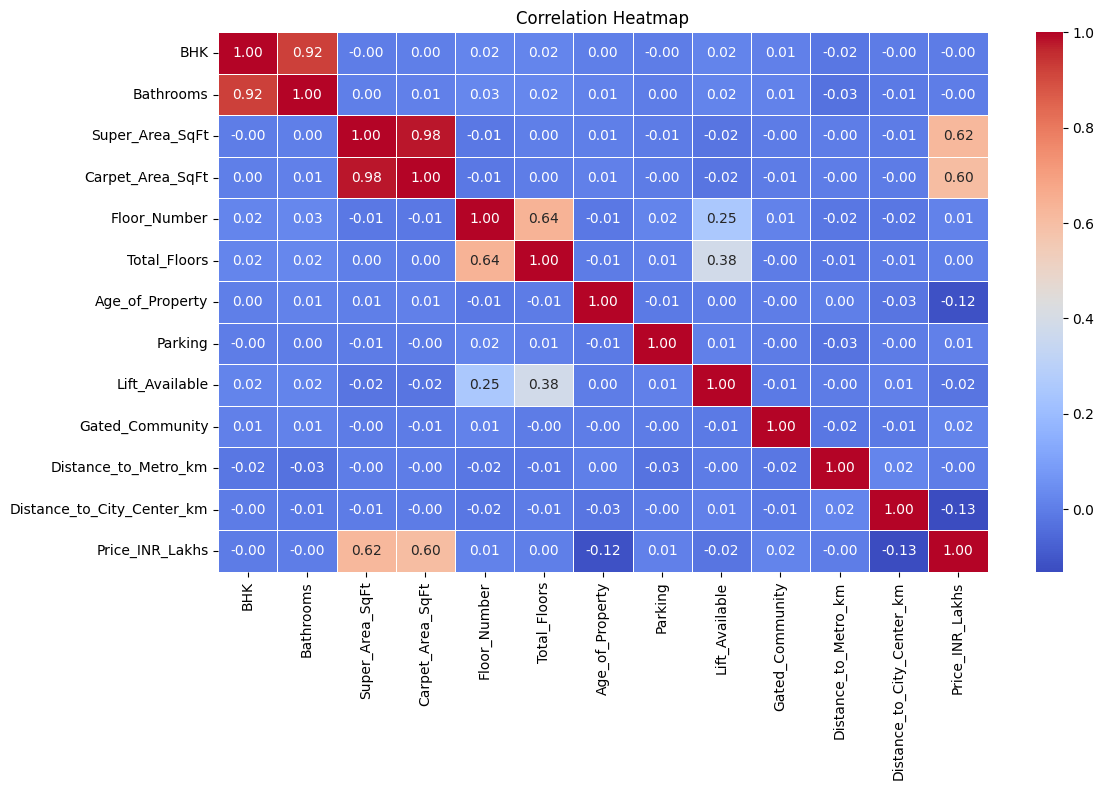

Correlation with house price:


,Price_INR_Lakhs
Price_INR_Lakhs,1.000000
Super_Area_SqFt,0.621794
Carpet_Area_SqFt,0.604536
Gated_Community,0.015288
Floor_Number,0.013441
Parking,0.007495
Total_Floors,0.001285
Bathrooms,-0.000781
Distance_to_Metro_km,-0.002789
BHK,-0.004261


In [11]:
numeric_df = df.select_dtypes(include=["number"]).drop(
    columns=["Property_ID"],
    errors="ignore"
)
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlation with house price:")
display(correlation["Price_INR_Lakhs"].sort_values(ascending=False).to_frame())

## 10. Identify Feature Types and Split the Dataset

In [12]:
numeric_data = X.select_dtypes(include=["number"]).columns.tolist()
cat_data = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:")
print(numeric_data)
print("\nCategorical features:")
print(cat_data)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat_data", OneHotEncoder(handle_unknown="ignore"), cat_data),
        ("numeric_data", StandardScaler(), numeric_data)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Numeric features:
['BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km']

Categorical features:
['City', 'Locality_Type', 'Property_Type', 'Furnishing_Status']
Total records: 5500
Training records: 4400
Testing records: 1100


## 11. Train the Linear Regression Model

In [13]:
Model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

Model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


## 12. Generate Linear Regression Predictions

In [14]:
y_pred = Model.predict(X_test)

print("First 10 predicted prices:")
print(y_pred[:10])

First 10 predicted prices:
[ 57.72468214 122.09904115  34.04279622 136.64202749  18.25979195
 172.63944095  83.13429706  29.05906937 332.11740071  14.97422789]


## 13. Evaluate the Linear Regression Model

In [15]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION EVALUATION RESULTS")
print("MAE:", round(mae, 2), "Lakhs")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "Lakhs")
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION EVALUATION RESULTS
MAE: 41.15 Lakhs
MSE: 4040.25
RMSE: 63.56 Lakhs
R2 Score: 0.6825


## 14. Implement and Compare Three Regression Algorithms

The target variable is continuous, so Decision Tree Regression and K-Nearest Neighbors Regression are used rather than their classification versions.

In [16]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

results = []
trained_models = {}

for name, algorithm in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", algorithm)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    results.append({
        "Algorithm": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

    trained_models[name] = model_pipeline

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,41.152,4040.250,63.563,0.682
1,Decision Tree,45.079,7092.464,84.217,0.443
2,KNN,52.069,7274.740,85.292,0.428


## 15. Five-Fold Cross-Validation

Cross-validation is performed on the training data. The test set remains separate for final evaluation.

In [19]:
cv_results = []

for name, algorithm in models.items():
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", algorithm)
    ])

    scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )

    cv_results.append({
        "Algorithm": name,
        "Mean CV R2": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.round(3))

,Algorithm,Mean CV R2,Standard Deviation
0,Linear Regression,0.665,0.041
1,Decision Tree,0.478,0.084
2,KNN,0.451,0.064


## 16. Hyperparameter Tuning

GridSearchCV tests parameter combinations using five-fold cross-validation and selects the configuration with the lowest cross-validation RMSE.

### 16.1 Tune Decision Tree Regression

In [20]:
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

dt_params = {
    "regressor__max_depth": [None, 5, 10, 15, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4]
}

dt_search = GridSearchCV(
    dt_pipeline,
    dt_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

print("Decision Tree best parameters:")
print(dt_search.best_params_)
print("Decision Tree best cross-validation RMSE:", round(-dt_search.best_score_, 3))

Decision Tree best parameters:
{'regressor__max_depth': 5, 'regressor__min_samples_leaf': 4, 'regressor__min_samples_split': 10}
Decision Tree best cross-validation RMSE: 72.464


### 16.2 Tune KNN Regression

In [21]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", KNeighborsRegressor())
])

knn_params = {
    "regressor__n_neighbors": [3, 5, 7, 9, 11],
    "regressor__weights": ["uniform", "distance"],
    "regressor__p": [1, 2]
}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("KNN best parameters:")
print(knn_search.best_params_)
print("KNN best cross-validation RMSE:", round(-knn_search.best_score_, 3))

KNN best parameters:
{'regressor__n_neighbors': 11, 'regressor__p': 1, 'regressor__weights': 'distance'}
KNN best cross-validation RMSE: 84.367


## 17. Compare the Final Tuned Models

In [22]:
final_models = {
    "Linear Regression": trained_models["Linear Regression"],
    "Tuned Decision Tree": dt_search.best_estimator_,
    "Tuned KNN": knn_search.best_estimator_
}

final_results = []
final_predictions = {}

for name, model in final_models.items():
    predictions = model.predict(X_test)
    final_predictions[name] = predictions

    final_results.append({
        "Algorithm": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

final_results_df = pd.DataFrame(final_results)
display(final_results_df.round(3))

best_model_name = final_results_df.sort_values(
    by=["R2 Score", "RMSE"],
    ascending=[False, True]
).iloc[0]["Algorithm"]

best_model = final_models[best_model_name]
y_pred_best = final_predictions[best_model_name]

print("Best model based on test R2 score:", best_model_name)

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,41.152,4040.250,63.563,0.682
1,Tuned Decision Tree,41.317,4306.704,65.625,0.662
2,Tuned KNN,45.708,5902.200,76.826,0.536


Best model based on test R2 score: Linear Regression


## 18. Actual Versus Predicted Prices

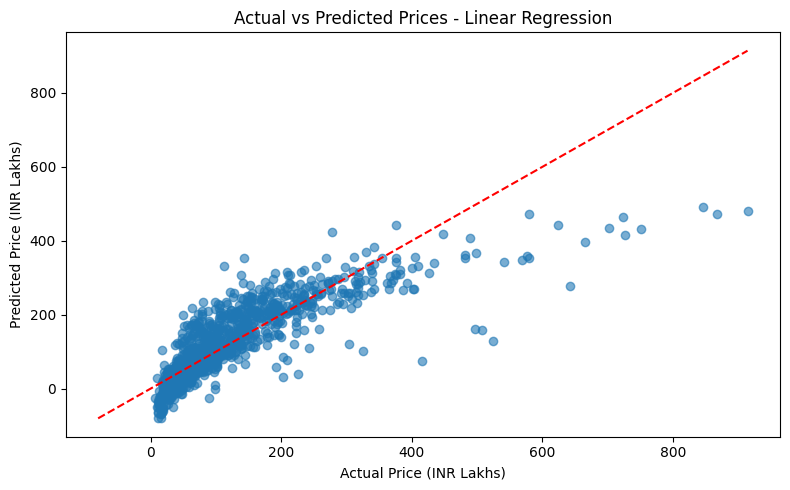

In [23]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_best, alpha=0.6)

minimum = min(y_test.min(), y_pred_best.min())
maximum = max(y_test.max(), y_pred_best.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Price (INR Lakhs)")
plt.ylabel("Predicted Price (INR Lakhs)")
plt.title(f"Actual vs Predicted Prices - {best_model_name}")
plt.tight_layout()
plt.show()

## 19. Residual Analysis

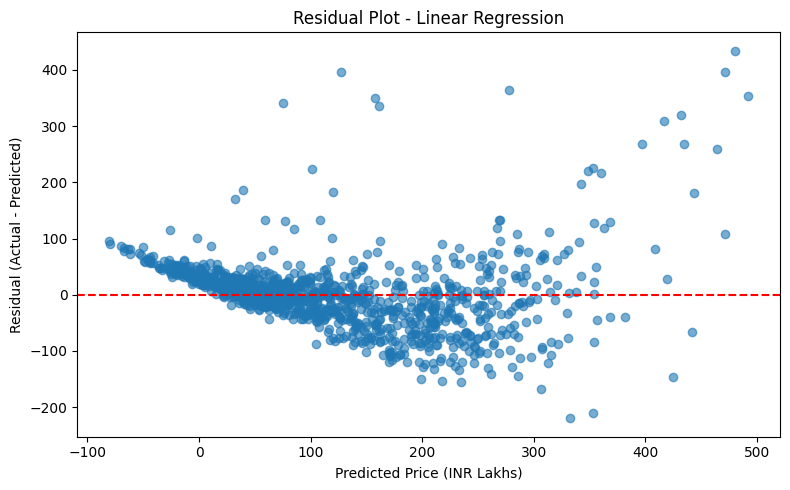

In [24]:
residuals = y_test - y_pred_best

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_best, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Price (INR Lakhs)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(f"Residual Plot - {best_model_name}")
plt.tight_layout()
plt.show()

## 20. Project Conclusion

Use the model comparison table and evaluation plots to discuss which algorithm performed best on the test data. Lower MAE and RMSE indicate smaller prediction errors, while a higher R² score indicates that the model explains more variation in house prices. Correlation indicates association, not causation.